# **Duke CYBERSEC 520 - Final Project: Phishing URL Triage**
### Evaluating detection across datasets & alert thresholds

| | |
|---|---|
| Name | **Gavin Gucwa** |
| Duke NetID | **gg217** |

### How to Run
1. Download both datasets into one folder:
   - **PhiUSIIL** (UCI): `PhiUSIIL_Phishing_URL_Dataset.csv`
   - **Malicious URLs dataset** (Kaggle): `malicious_phish.csv`, columns `url` and `type` (the folder may be nested, the notebook searches subfolders)
2. Edit the file pathway to match the folder's location (comment will show what to edit)
3. Keep the `deploy/` folder next to this notebook. It holds `features.py`, which is shared between this notebook and the Gradio app so training and deployment always compute features the same way.
4. Run all cells. Trained models are saved to `deploy/models/` for the app.

Note: USE_MOCK=1 runs the full pipeline on small synthetic data (separate output folders, nothing is written to `deploy/`). This should only be used to test the code. Its metrics mean nothing.

No API keys or tokens are used in this project. The app never visits a submitted URL.

### 1. Problem Identification

**The problem.** Phishing is still one of the most common ways attackers get credentials and a first foothold in an organization. Companies run simulated phishing campaigns, hold security training, and filter email, but some dangerous links still reach inboxes. One clicked link can lead to credential theft and unauthorized account access.

**Why it matters.** Blocklists and reputation feeds only know about URLs that were already reported, so brand-new links are exposed. Content-based scanners need to fetch the page, which is slow and can be evaded. A fast, lightweight model that scores a URL from its text alone can help a triage analyst decide which unfamiliar links to look at first. If the problem is left unsolved, analysts either drown in alerts or phishing links get through.

**Current solutions.** Blocklists and reputation services, secure email gateways, browser warnings, sandboxing / page detonation, and user training. Each has gaps: blocklists lag behind new URLs, sandboxing is expensive, and training depends on people.

**Research question.** How well can machine learning separate phishing URLs from legitimate URLs using the URL text alone, and how does that performance change (a) on an independent dataset from a different source and (b) when the alert threshold is tuned to a low false-positive budget?

False positives matter just as much as misses here, since every wrongly flagged legitimate link creates review work and erodes trust in the tool.

### Threat Model

| Component | Details |
|---|---|
| Threat actor | Financially motivated phisher who can register domains, craft URLs, or compromise legitimate websites. Moderate resources, high volume, low cost per attempt. |
| Motivation | Steal credentials or gain unauthorized access |
| Targets | Employees and the business accounts they use (email, SSO, finance, cloud apps) |
| Attacker capabilities | Modify URL structure, use redirects / shortened links, host phishing pages on legitimate domains |
| Evasion considerations | Build URLs that look like legitimate links (short, clean, no digits or extra symbols), hide the real destination behind a shortener, or use a compromised legitimate domain so URL text alone looks normal. A feature-based model can also be probed: an attacker who learns the features can mutate a URL until the score drops. |
| Defensive placement | Advisory tool that supports email / security triage. It sits beside (not instead of) blocklists, gateways, and analyst review. |
| False-negative impact | A phishing URL is not flagged, leaving the user exposed |
| False-positive impact | A legitimate URL creates an unnecessary warning or review task, which costs analyst time and causes alert fatigue |

*Important note: website content and redirect destinations are outside of the model's visibility. The model only sees the URL string.*

### Solution Overview

A user submits a URL → the app validates and parses the input → a shared preprocessing pipeline (`features.py`) extracts URL-only features → a trained model produces a phishing score → the interface shows the result and a recommendation for review.

| Model | Reasoning | Potential limitation |
|---|---|---|
| Logistic Regression | Simple, fast, interpretable baseline. Coefficients show which features push a URL toward phishing. | Could miss complex relationships between features |
| Random Forest | Captures nonlinear relationships and feature interactions without much scaling | Could overfit patterns specific to the training set |

### Setup & Library Confirmation

In [1]:
%pip install -q pandas scikit-learn matplotlib joblib numpy

Note: you may need to restart the kernel to use updated packages.


### Settings Summary

| Setting | Details |
|---|---|
| Primary dataset | PhiUSIIL Phishing URL Dataset (UCI). Used for training, validation, and internal testing. Only the `URL` and `label` columns are used so the model stays URL-only. |
| Secondary dataset | Kaggle Malicious URLs dataset (`malicious_phish.csv`), `benign` and `phishing` rows only (malware and defacement are excluded). Used ONLY for external testing. See the dataset search notes below. |
| Labels | `label` 0 = phishing, 1 = legitimate (matches PhiUSIIL). Metrics treat **phishing as the positive class**, and all thresholds apply to the phishing-class score. |
| Preprocessing | Only the hostname is lowercased (path and query keep their case). The scheme (http/https), a leading `www.` and a root-only trailing slash (`example.com/` becomes `example.com`) are removed. These are **modeling choices** that put two differently collected datasets into one format, not claims that such URLs are always equivalent. Same function for both datasets and for the app. See the change log below. |
| Features | 24 URL-only features (lengths, subdomain count, digit ratio, IP in hostname, special characters, entropy, etc.). Listed in `deploy/features.py`. |
| Cleaning | Remove empty/unparseable URLs, drop URLs with conflicting labels, drop duplicates, remove secondary URLs that also appear in the primary data. Every count is saved to `data_audit.csv`. |
| Split | Primary data is split **grouped by registered domain**: 70% train / 15% validation / 15% test, `random_state=520`. No domain appears in more than one split. |
| Models | Logistic Regression (log1p + standard scaling) and Random Forest |
| Tuning | Validation set only. Selection metric is phishing-class Average Precision (AP, from `average_precision_score`), a summary of the precision-recall curve. |
| Thresholds | Default 0.5 vs. a threshold picked on validation data to maximize recall under a 1% false-positive rate. |
| Freeze | Model settings and thresholds are written to `config.json` BEFORE either test set is scored. The secondary dataset was excluded from model fitting and from hyperparameter and threshold selection. However, its early results informed the v2 preprocessing change (see the change log), so the secondary results are an **exploratory external evaluation**, not a fully untouched test. |
| Reproducibility | Seeds, feature list, model settings, and software versions are all stored in `config.json`. |
| Environment | `requirements.txt` and the Dockerfile's Python version are generated from the training environment recorded in `config.json`. The app refuses to start if scikit-learn, numpy, pandas, joblib or the Python minor version differ, and the Docker build runs `test_features.py` and `smoke_test.py`. |

### Settings & Imports

In [10]:
import os, sys, json, time, re, platform
from copy import deepcopy
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import joblib
import sklearn
import warnings
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    confusion_matrix, precision_recall_curve, roc_curve
)

#THIS IS WHERE YOU INSERT YOUR OWN FOLDER PATH
folder_path = Path(r"C:\Users\gavin\Downloads\Final Project\project\deploy\Datasets")

SEED = 520
MOCK = os.environ.get("USE_MOCK") == "1"
MAX_FPR = 0.01          # false-positive budget used to pick the tuned threshold
PREVALENCE = 0.01       # ASSUMPTION for the business table only: 1 in 100 URLs is phishing

PRIMARY_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"
SECONDARY_FILE = "malicious_phish.csv"
SECONDARY_URL_COL = "url"
SECONDARY_TYPE_COL = "type"
SECONDARY_LABELS = {"benign": 1, "phishing": 0}   # every other type (malware, defacement) is excluded

DEPLOY_DIR = Path("deploy")

# Safety checks BEFORE anything is created: make sure the notebook is running next to the deploy/ folder
sys.dont_write_bytecode = True        # stops Python from creating __pycache__ folders
print("Notebook is running from:", Path.cwd().resolve())
if not (DEPLOY_DIR / "features.py").exists():
    raise FileNotFoundError(
        "deploy/features.py was not found next to this notebook. Start Jupyter from the folder that contains "
        "this notebook and the deploy folder, then run again. Nothing was created."
    )

OUT_DIR = Path("outputs_mock" if MOCK else "outputs")
MODEL_DIR = Path("deploy_mock/models" if MOCK else "deploy/models")
OUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# features.py is shared with the Gradio app
sys.path.insert(0, str(DEPLOY_DIR))
from features import (
    FEATURES, normalize_url, split_url, registered_domain,
    features_frame, phish_score, check_url_input
)

print("Mock mode:", MOCK)
print("Number of features:", len(FEATURES))
print("Data folder :", folder_path.resolve())
print("Outputs go to:", OUT_DIR.resolve())
print("Models go to :", MODEL_DIR.resolve())

Notebook is running from: C:\Users\gavin\Downloads\Final Project\project
Mock mode: False
Number of features: 24
Data folder : C:\Users\gavin\Downloads\Final Project\project\deploy\Datasets
Outputs go to: C:\Users\gavin\Downloads\Final Project\project\outputs
Models go to : C:\Users\gavin\Downloads\Final Project\project\deploy\models


### Preprocessing Change Log (read this)

**v1 (first full run):** URLs were lowercased entirely and the scheme and `www.` were stripped. Results on the secondary dataset collapsed: both models flagged about 100% of legitimate URLs (false-positive rate about 1.00, secondary Average Precision 0.13 to 0.14, below the 17% phishing base rate). Diagnosis showed (a) PhiUSIIL's test set contained **no legitimate URLs with a path**, so the models partly learned "has a path = phishing", and (b) 99.4% of the secondary dataset's legitimate bare-domain URLs ended in a trailing `/` while 0% of PhiUSIIL's did, which changed `num_slashes` (the models' top feature) for what is the same homepage. A hostname-only post-hoc experiment stopped the collapse but caught very little phishing.

**v2:** `normalize_url` also removed a root-only trailing slash. Secondary legitimate bare-domain URLs flagged fell from 99.8% to 28.2%, but the overall secondary false-positive rate stayed at about 90% to 92%, because 89% of the secondary legitimate URLs have a path and PhiUSIIL has none.

**v3 (this version):** changes made after an external code review.
- `normalize_url` now lowercases only the hostname. Paths and query values keep their case, because they can be case-sensitive (`/Account?Token=AbC` and `/account?token=abc` are no longer the same example). Removing the scheme, `www.` and a root slash is documented as a *modeling decision*, not a claim of URL equivalence.
- The metric is called Average Precision (AP) everywhere, because it is computed with `average_precision_score`.
- App input validation is stricter (supported schemes, hostname structure, numeric ports, IP addresses) and has tests. The app also checks library versions and the Docker build runs a smoke test.
- Everything is retrained from scratch, so v3 numbers differ slightly from v2.

**Independence note:** the secondary dataset was excluded from model fitting and from hyperparameter and threshold selection. However, its initial results informed the v2 normalization change and the post-hoc diagnostics, so the v2 and v3 secondary results are an **exploratory external evaluation, not a fully untouched test**. A fresh blind assessment would need a newly reserved external dataset. Writing a configuration file before scoring does not undo what was learned in an earlier run.

In [7]:
# format checks for the shared normalization function (a modeling view of a URL, not URL equivalence)
assert normalize_url("HTTP://www.Example.com/") == "example.com"
assert normalize_url("https://example.com") == "example.com"
assert normalize_url("example.com/a/") == "example.com/a/"
assert normalize_url("example.com/?x=1") == "example.com/?x=1"
assert normalize_url("HTTP://www.Example.com/Account?Token=AbC") == "example.com/Account?Token=AbC"
assert normalize_url("example.com/Account?Token=AbC") != normalize_url("example.com/account?token=abc")
print("Normalization tests passed.")

# input validation used by the app (the full list of cases is in deploy/test_features.py)
for good in ["https://example.com", "example.com/login", "http://[2001:db8::1]/x", "https://example.com:8080/a"]:
    assert check_url_input(good)[1] is None, good
for bad in ["", "hello", "javascript:alert(1)", "https://example.com:abc/a", "https://999.999.999.999/a", "ftp://example.com/x"]:
    assert check_url_input(bad)[1] is not None, bad
print("Input validation tests passed.")

Normalization tests passed.
Input validation tests passed.


### Mock Data (only used when USE_MOCK=1)
Creates small fake datasets in the same file formats as the real ones so the code can be tested without downloading anything. It also injects duplicates, conflicting labels, and overlapping URLs so the audit steps have something to find.

In [8]:
def make_mock_data(folder):
    rng = np.random.default_rng(SEED)
    words = ["alpha", "bravo", "cedar", "delta", "ember", "flint", "grove", "harbor", "iris", "juniper",
             "kite", "lumen", "maple", "nova", "onyx", "pine", "quartz", "river", "stone", "tidal",
             "umber", "vivid", "willow", "xenon", "yarrow", "zephyr", "bank", "pay", "mail", "cloud"]
    tlds = ["com", "org", "net", "edu", "io", "co.uk"]

    def pick(n):
        return "/".join(rng.choice(words, n))

    legit_domains = [f"{rng.choice(words)}{rng.choice(words)}.{rng.choice(tlds)}" for _ in range(600)]

    def legit(style):
        d = rng.choice(legit_domains)
        path = pick(rng.integers(0, 3))
        url = f"{d}/{path}"
        if rng.random() < 0.10:
            url += f"?id={rng.integers(1000, 99999)}&ref={pick(1)}"
        return ("https://www." if style == "primary" else "http://") + url

    def phish(style):
        if rng.random() < 0.15:                      # looks clean on purpose
            return legit(style)
        if rng.random() < 0.20:                      # raw IP host
            host = ".".join(str(x) for x in rng.integers(1, 255, 4))
        else:
            sub = "-".join(rng.choice(words, rng.integers(1, 3))) + str(rng.integers(0, 999))
            host = f"{sub}.{rng.choice(words)}-{rng.choice(words)}{rng.integers(0, 99)}.{rng.choice(tlds)}"
        path = pick(rng.integers(1, 5)) + f"/login.php?user={rng.integers(10**5, 10**9)}&token={rng.integers(10**8, 10**12)}"
        return ("https://" if style == "primary" else "http://") + host + "/" + path

    # primary: PhiUSIIL-style csv (FILENAME, URL, label with 1 = legit)
    rows = [(legit("primary"), 1) for _ in range(4000)] + [(phish("primary"), 0) for _ in range(3000)]
    prim = pd.DataFrame(rows, columns=["URL", "label"])
    prim = pd.concat([prim, prim.sample(40, random_state=SEED)])                          # duplicates
    conflict = prim.sample(10, random_state=1).copy(); conflict["label"] = 1 - conflict["label"]
    prim = pd.concat([prim, conflict]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    prim.insert(0, "FILENAME", [f"{i}.txt" for i in range(len(prim))])
    folder.mkdir(parents=True, exist_ok=True)
    prim.to_csv(folder / PRIMARY_FILE, index=False)

    # secondary: Kaggle-style csv (url, type), slightly different style, with some overlap and other types
    benign = [legit("secondary") for _ in range(2000)] + prim[prim["label"] == 1]["URL"].head(30).tolist()
    phishing = [phish("secondary") for _ in range(1000)] + prim[prim["label"] == 0]["URL"].head(20).tolist()
    other = [phish("secondary") for _ in range(100)]
    sec = pd.DataFrame({
        "url": benign + phishing + other,
        "type": ["benign"] * len(benign) + ["phishing"] * len(phishing) + ["malware"] * len(other),
    }).sample(frac=1, random_state=SEED)
    sec.to_csv(folder / SECONDARY_FILE, index=False)

if MOCK:
    folder_path = Path("mock_data")
    make_mock_data(folder_path)
    print("Mock data written to", folder_path)

### Secondary Dataset Search (documented change from the proposal)

The proposal planned to use **ISCX-URL2016** as the secondary dataset. During the data feasibility check it turned out to be unsuitable:

| Candidate | Finding | Decision |
|---|---|---|
| ISCX-URL2016 (UNB / IEEE DataPort) | The public download is a set of precomputed feature tables (`All.csv`: 36,707 rows, 79 numeric features + a type label). It contains **no URL text**. Its features follow the original authors' definitions, so they cannot be matched to this project's URL-only features without the raw URLs, and the deployed app (which sees raw URLs) would not use the same inputs. | Not used |
| Kaggle Malicious URLs dataset (`malicious_phish.csv`) | Raw URLs with a `type` label (benign, phishing, malware, defacement). Different source mix and collection method than PhiUSIIL. Benign and phishing rows can go through the identical `features.py` pipeline. | **Used as the secondary dataset** |

Because the Kaggle file is a compilation, some of its URLs may also exist in other public datasets. Overlap with PhiUSIIL is checked and removed below, and its labels are treated as imperfect (see Limitations).

### 2. Data Collection & Loading

Before using either dataset, confirm that the files exist, the URL field is usable, the label definitions match, and note the dataset terms (both are published for research use; check each source page before redistributing).

In [11]:
def find_file(folder, name):
    matches = list(Path(folder).rglob(name))
    if not matches:
        found = [p.name for p in Path(folder).rglob("*") if p.is_file()][:20]
        raise FileNotFoundError(f"Could not find {name} under {folder}. Files seen: {found}")
    return matches[0]

# Primary: only the URL text and the label are used
primary_raw = pd.read_csv(find_file(folder_path, PRIMARY_FILE), usecols=["URL", "label"])
primary_raw = primary_raw.rename(columns={"URL": "url"})
primary_raw["dataset"] = "primary"

# Secondary: keep only benign and phishing rows, map them to the primary label convention (0 = phishing, 1 = legitimate)
secondary_all = pd.read_csv(find_file(folder_path, SECONDARY_FILE), usecols=[SECONDARY_URL_COL, SECONDARY_TYPE_COL])
secondary_all = secondary_all.rename(columns={SECONDARY_URL_COL: "url", SECONDARY_TYPE_COL: "type"})
secondary_all["type"] = secondary_all["type"].astype(str).str.strip().str.lower()
print("Secondary types in file:", secondary_all["type"].value_counts().to_dict())

secondary_raw = secondary_all[secondary_all["type"].isin(SECONDARY_LABELS)].copy()
secondary_raw["label"] = secondary_raw["type"].map(SECONDARY_LABELS)
secondary_raw = secondary_raw[["url", "label"]].reset_index(drop=True)
secondary_raw["dataset"] = "secondary"

for name, df in (("Primary (PhiUSIIL)", primary_raw), ("Secondary (Kaggle Malicious URLs)", secondary_raw)):
    print(name, df.shape)
    print("  label counts (0 = phishing, 1 = legitimate):", df["label"].value_counts().to_dict())
assert set(primary_raw["label"].unique()) <= {0, 1}
assert set(secondary_raw["label"].unique()) <= {0, 1}

Secondary types in file: {'benign': 428103, 'defacement': 96457, 'phishing': 94111, 'malware': 32520}
Primary (PhiUSIIL) (235795, 3)
  label counts (0 = phishing, 1 = legitimate): {1: 134850, 0: 100945}
Secondary (Kaggle Malicious URLs) (522214, 3)
  label counts (0 = phishing, 1 = legitimate): {1: 428103, 0: 94111}


### 3. Cleaning & Audit

Steps (same function for both datasets):
1. Remove missing / empty URLs
2. Normalize each URL (lowercase, scheme and `www.` removed). Two URLs that only differ by `http` vs `https` count as duplicates.
3. Drop every URL that appears with **conflicting labels** (can't be trusted)
4. Drop exact duplicates
5. Drop URLs that cannot be parsed into features

In [12]:
def clean_dataset(df, name):
    audit = {"dataset": name, "raw_rows": len(df)}

    df = df.dropna(subset=["url"]).copy()
    df["url"] = df["url"].astype(str).str.strip()
    df["key"] = df["url"].map(normalize_url)
    df = df[df["key"] != ""]
    audit["after_empty_removed"] = len(df)

    n_labels = df.groupby("key")["label"].nunique()
    conflict_keys = n_labels[n_labels > 1].index
    audit["conflicting_label_urls"] = len(conflict_keys)
    df = df[~df["key"].isin(conflict_keys)]

    before = len(df)
    df = df.drop_duplicates("key")
    audit["duplicates_removed"] = before - len(df)

    return df.reset_index(drop=True), audit

primary, audit_p = clean_dataset(primary_raw, "primary")
secondary, audit_s = clean_dataset(secondary_raw, "secondary")

# Overlap between datasets: secondary URLs that also appear in the primary data are removed from the secondary set
overlap_mask = secondary["key"].isin(set(primary["key"]))
audit_s["overlap_with_primary_removed"] = int(overlap_mask.sum())
secondary = secondary[~overlap_mask].reset_index(drop=True)

print("Primary after cleaning:", primary.shape)
print("Secondary after cleaning:", secondary.shape)
print("Secondary URLs removed for overlapping with primary:", audit_s["overlap_with_primary_removed"])

Primary after cleaning: (232472, 4)
Secondary after cleaning: (510840, 4)
Secondary URLs removed for overlapping with primary: 1231


### 4. Feature Extraction

The same `features_frame` function builds features for both datasets (and later for the app). The registered domain of each URL is also stored so the primary split can be grouped by domain.

In [13]:
def build_table(df):
    start = time.time()
    feats = features_frame(df["url"])
    table = pd.concat([df.reset_index(drop=True), feats], axis=1)
    bad = (~table["ok"]).sum()
    table = table[table["ok"]].drop(columns="ok").reset_index(drop=True)
    table["domain"] = [registered_domain(split_url(u)[2]) for u in table["url"]]
    table["phish"] = 1 - table["label"]          # 1 = phishing = positive class for every metric
    print(f"{len(table)} URLs featurized, {bad} unparseable dropped ({time.time() - start:.0f}s)")
    return table, int(bad)

primary_t, bad_p = build_table(primary)
secondary_t, bad_s = build_table(secondary)
audit_p["unparseable_removed"] = bad_p
audit_s["unparseable_removed"] = bad_s
audit_p["final_rows"] = len(primary_t)
audit_s["final_rows"] = len(secondary_t)
audit_p["final_phishing"] = int(primary_t["phish"].sum())
audit_s["final_phishing"] = int(secondary_t["phish"].sum())

audit = pd.DataFrame([audit_p, audit_s]).fillna(0).astype({"overlap_with_primary_removed": int}, errors="ignore")
audit.to_csv(OUT_DIR / "data_audit.csv", index=False)
audit.T

232472 URLs featurized, 0 unparseable dropped (33s)
510823 URLs featurized, 17 unparseable dropped (88s)


,0,1
dataset,primary,secondary
raw_rows,235795,522214
after_empty_removed,235795,522214
conflicting_label_urls,43,4047
duplicates_removed,3237,1911
unparseable_removed,0,17
final_rows,232472,510823
final_phishing,97665,88891
overlap_with_primary_removed,0,1231


### Dataset Discrepancy Check (primary vs. secondary)

A model can look great on its own dataset just by learning how that dataset was collected. This compares the two sources on things that have nothing to do with phishing itself (URL style, scheme, `www.`) and on the model features. These gaps are why the scheme and `www.` are stripped before feature extraction.

In [14]:
combined = pd.concat([primary_t, secondary_t], ignore_index=True)
combined["class"] = combined["phish"].map({1: "phishing", 0: "legitimate"})
combined["https"] = combined["url"].str.lower().str.startswith("https")
combined["www"] = combined["url"].str.lower().str.contains(r"^(?:[a-z]+://)?www\.", regex=True)

style = combined.groupby(["dataset", "class"]).agg(
    n=("url", "size"),
    share_https=("https", "mean"),
    share_www=("www", "mean"),
    median_url_length=("url_length", "median"),
    median_subdomains=("subdomain_count", "median"),
    share_ip_host=("has_ip_host", "mean"),
    median_digit_ratio=("digit_ratio", "median"),
).round(3)
style.to_csv(OUT_DIR / "dataset_discrepancies.csv")
style

n  share_https  share_www  median_url_length  \
dataset   class                                                           
primary   legitimate  134807        1.000      1.000               15.0   
          phishing     97665        0.487      0.417               25.0   
secondary legitimate  421932        0.004      0.028               46.0   
          phishing     88891        0.072      0.395               30.0   

                      median_subdomains  share_ip_host  median_digit_ratio  
dataset   class                                                             
primary   legitimate                0.0          0.000               0.000  
          phishing                  1.0          0.006               0.000  
secondary legitimate                0.0          0.000               0.032  
          phishing                  0.0          0.004               0.000

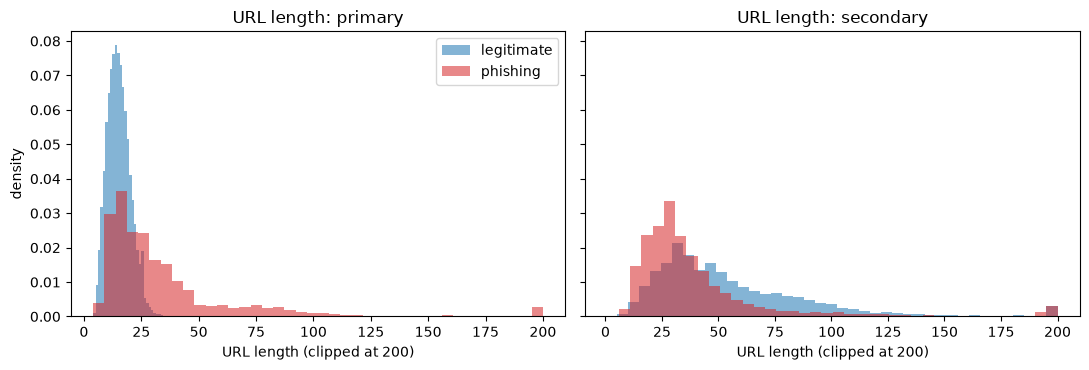

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ds in zip(axes, ["primary", "secondary"]):
    for cls, color in (("legitimate", "tab:blue"), ("phishing", "tab:red")):
        vals = combined[(combined["dataset"] == ds) & (combined["class"] == cls)]["url_length"].clip(upper=200)
        ax.hist(vals, bins=40, alpha=0.55, density=True, label=cls, color=color)
    ax.set_title(f"URL length: {ds}")
    ax.set_xlabel("URL length (clipped at 200)")
axes[0].set_ylabel("density")
axes[0].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "url_length_by_dataset.png", dpi=150)
plt.show()

### 5. Split Primary Data (grouped by domain)

Random splits would put URLs from the same domain in both train and test, which lets a model memorize domains. Grouping by registered domain avoids that. The secondary dataset is never split or used for training.

In [16]:
groups = primary_t["domain"]

outer = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(outer.split(primary_t, groups=groups))
trainval = primary_t.iloc[trainval_idx]
test_primary = primary_t.iloc[test_idx].reset_index(drop=True)

inner = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
train_idx, val_idx = next(inner.split(trainval, groups=trainval["domain"]))
train = trainval.iloc[train_idx].reset_index(drop=True)
val = trainval.iloc[val_idx].reset_index(drop=True)

print("Train:", len(train), "| Validation:", len(val), "| Primary test:", len(test_primary), "| Secondary test:", len(secondary_t))

# no domain may appear in more than one split
assert not set(train["domain"]) & set(val["domain"])
assert not set(train["domain"]) & set(test_primary["domain"])
assert not set(val["domain"]) & set(test_primary["domain"])
for name, df in (("train", train), ("val", val), ("test_primary", test_primary), ("secondary", secondary_t)):
    assert df["phish"].nunique() == 2, f"{name} is missing a class"
    print(f"  {name}: {df['phish'].mean():.1%} phishing")

pd.concat([
    train.assign(split="train"), val.assign(split="val"), test_primary.assign(split="test_primary")
])[["key", "domain", "split"]].to_csv(OUT_DIR / "split_ids.csv", index=False)

X_train, y_train = train[FEATURES], train["phish"]
X_val, y_val = val[FEATURES], val["phish"]
X_test, y_test = test_primary[FEATURES], test_primary["phish"]
X_sec, y_sec = secondary_t[FEATURES], secondary_t["phish"]

Train: 166036 | Validation: 33964 | Primary test: 32472 | Secondary test: 510823
  train: 42.9% phishing
  val: 40.9% phishing
  test_primary: 38.6% phishing
  secondary: 17.4% phishing


### 6. Model Design & Implementation

| Model | Architecture | Settings tuned on validation |
|---|---|---|
| Logistic Regression | `log1p` transform → standard scaling → logistic regression. The log transform tames heavy-tailed length and count features. All learned steps (scaling, coefficients) are fit on the training split only. | Regularization strength `C` |
| Random Forest | Ensemble of decision trees on the raw features (no scaling needed) | Number of trees, max depth |

Both models are trained on the **same split**. Phishing is the positive class (`y = 1`), so `predict_proba(...)[:, 1]` is the phishing score everywhere (notebook and app). Settings are chosen by validation Average Precision (AP).

In [17]:
def make_lr(C):
    return Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=2000, random_state=SEED)),
    ])

def make_rf(n_estimators, max_depth):
    return RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, n_jobs=-1, random_state=SEED)

GRIDS = {
    "Logistic Regression": (make_lr, [{"C": c} for c in (0.01, 0.1, 1, 10)]),
    "Random Forest": (make_rf, [{"n_estimators": n, "max_depth": d} for n in (100, 200) for d in (10, 20, None)]),
}

tuning_rows = []
best_models, best_params = {}, {}

for name, (builder, settings) in GRIDS.items():
    best_ap = -1
    for params in settings:
        model = builder(**params)
        model.fit(X_train, y_train)
        scores = model.predict_proba(X_val)[:, 1]
        ap = average_precision_score(y_val, scores)
        tuning_rows.append({
            "model": name,
            "settings": str(params),
            "val_ap": ap,
            "val_f1_at_0.5": f1_score(y_val, scores >= 0.5, zero_division=0),
        })
        if ap > best_ap:
            best_ap, best_models[name], best_params[name] = ap, model, params

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(OUT_DIR / "validation_tuning.csv", index=False)
print("Selected settings:", best_params)
tuning.round(4)

Selected settings: {'Logistic Regression': {'C': 1}, 'Random Forest': {'n_estimators': 200, 'max_depth': 10}}


,model,settings,val_ap,val_f1_at_0.5
0,Logistic Regression,{'C': 0.01},0.8713,0.7829
1,Logistic Regression,{'C': 0.1},0.8722,0.7834
2,Logistic Regression,{'C': 1},0.8723,0.7831
3,Logistic Regression,{'C': 10},0.8723,0.7831
4,Random Forest,"{'n_estimators': 100, 'max_depth': 10}",0.8923,0.7934
5,Random Forest,"{'n_estimators': 100, 'max_depth': 20}",0.8882,0.7936
6,Random Forest,"{'n_estimators': 100, 'max_depth': None}",0.8836,0.7917
7,Random Forest,"{'n_estimators': 200, 'max_depth': 10}",0.8924,0.7929
8,Random Forest,"{'n_estimators': 200, 'max_depth': 20}",0.8884,0.7929
9,Random Forest,"{'n_estimators': 200, 'max_depth': None}",0.8840,0.7915


### 7. Threshold Selection & Freeze

Two operating points per model:
- **Default**: 0.5 on the phishing score
- **Tuned**: the threshold that gives the highest recall while keeping the validation false-positive rate at or below 1%. This is experimental and not a promised result. If recall comes out poor, that tradeoff is reported as is.

Everything is written to `config.json` **before** either test set is scored.

In [18]:
def pick_threshold(y_true, scores, max_fpr=MAX_FPR):
    fpr, tpr, thr = roc_curve(y_true, scores)
    within_budget = np.where(fpr <= max_fpr)[0]
    i = within_budget[-1]                                  # highest recall inside the FPR budget
    return float(thr[i]) if np.isfinite(thr[i]) else 1.0

thresholds, threshold_rows = {}, []
for name, model in best_models.items():
    scores = model.predict_proba(X_val)[:, 1]
    tuned = pick_threshold(y_val, scores)
    thresholds[name] = {"default": 0.5, "tuned": tuned}
    for kind, t in thresholds[name].items():
        pred = scores >= t
        tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
        threshold_rows.append({
            "model": name, "threshold_type": kind, "threshold": round(t, 4),
            "val_recall": tp / (tp + fn), "val_fpr": fp / (fp + tn),
        })

threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(OUT_DIR / "validation_thresholds.csv", index=False)

config = {
    "seed": SEED,
    "features": FEATURES,
    "max_fpr_budget": MAX_FPR,
    "model_settings": {k: {kk: (None if vv is None else vv) for kk, vv in v.items()} for k, v in best_params.items()},
    "thresholds": thresholds,
    "split": {"train": len(train), "val": len(val), "test_primary": len(test_primary), "secondary": len(secondary_t)},
    "versions": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
}
with open(MODEL_DIR / "config.json", "w") as file:
    json.dump(config, file, indent=2)

FROZEN = True
print("Settings and thresholds frozen. Test data has not been scored yet.")
threshold_table.round(4)

Settings and thresholds frozen. Test data has not been scored yet.


,model,threshold_type,threshold,val_recall,val_fpr
0,Logistic Regression,default,0.5000,0.6906,0.0507
1,Logistic Regression,tuned,0.7519,0.6188,0.0100
2,Random Forest,default,0.5000,0.6799,0.0242
3,Random Forest,tuned,0.6600,0.6533,0.0100


### 8. Evaluation

**Metrics (phishing = positive class):**

| Measure | What it tells |
|---|---|
| Precision | How many flagged URLs are actually phishing |
| Recall | How many phishing URLs the model catches |
| F1 score | The balance between precision and recall |
| False-positive rate | How often legitimate URLs are incorrectly flagged |
| Precision-Recall curve / Average Precision (AP) | How performance changes across thresholds. AP summarizes the curve and is computed with `average_precision_score`. |
| Inference latency | How quickly the deployed tool responds |

Accuracy is left out on purpose because it hides the tradeoffs that matter for triage. Every model is scored on the primary held-out test set AND the secondary dataset with the frozen settings.

In [19]:
assert FROZEN, "Freeze settings before touching test data"

with open(MODEL_DIR / "config.json") as file:
    frozen = json.load(file)

def evaluate(y_true, scores, threshold):
    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "n": len(y_true),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "fpr": fp / (fp + tn),
        "ap": average_precision_score(y_true, scores),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }

eval_sets = {"primary_test": (X_test, y_test), "secondary": (X_sec, y_sec)}
test_scores = {
    (ds, name): model.predict_proba(X)[:, 1]
    for name, model in best_models.items()
    for ds, (X, y) in eval_sets.items()
}

rows = []
for (ds, name), scores in test_scores.items():
    y = eval_sets[ds][1]
    for kind, t in frozen["thresholds"][name].items():
        rows.append({"dataset": ds, "model": name, "threshold_type": kind, "threshold": round(t, 4),
                     **evaluate(y, scores, t)})

results = pd.DataFrame(rows).sort_values(["dataset", "model", "threshold_type"]).reset_index(drop=True)
results.to_csv(OUT_DIR / "test_results.csv", index=False)
results.round(3)

,dataset,model,threshold_type,threshold,n,precision,recall,f1,fpr,ap,tp,fp,fn,tn
0,primary_test,Logistic Regression,default,0.500,32472,0.892,0.657,0.757,0.050,0.849,8230,999,4299,18944
1,primary_test,Logistic Regression,tuned,0.752,32472,0.965,0.571,0.717,0.013,0.849,7155,261,5374,19682
2,primary_test,Random Forest,default,0.500,32472,0.952,0.648,0.772,0.020,0.873,8124,406,4405,19537
3,primary_test,Random Forest,tuned,0.660,32472,0.980,0.622,0.761,0.008,0.873,7796,157,4733,19786
4,secondary,Logistic Regression,default,0.500,510823,0.160,0.840,0.269,0.928,0.129,74675,391420,14216,30512
5,secondary,Logistic Regression,tuned,0.752,510823,0.158,0.803,0.264,0.904,0.129,71416,381243,17475,40689
6,secondary,Random Forest,default,0.500,510823,0.159,0.827,0.266,0.924,0.122,73553,389958,15338,31974
7,secondary,Random Forest,tuned,0.660,510823,0.158,0.819,0.264,0.921,0.122,72771,388761,16120,33171


### Precision-Recall Curves
Circles mark the default 0.5 threshold, squares mark the tuned threshold chosen on validation data.

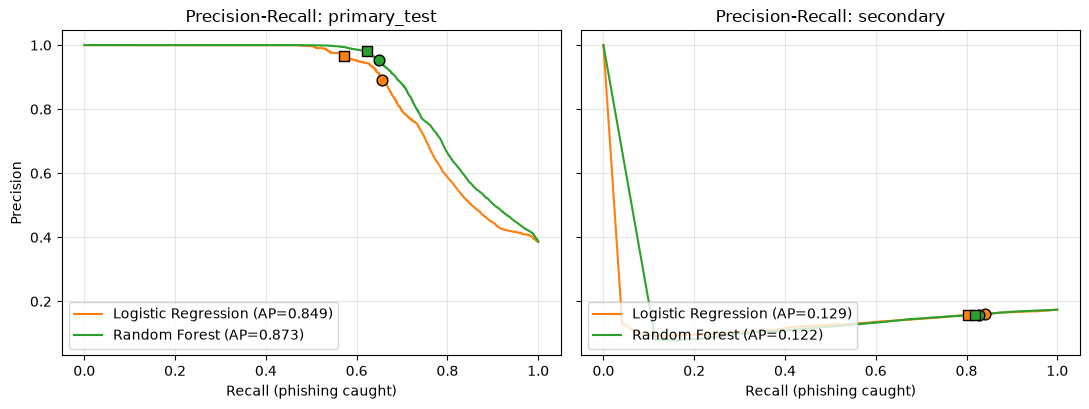

In [20]:
colors = {"Logistic Regression": "tab:orange", "Random Forest": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, ds in zip(axes, eval_sets):
    y = eval_sets[ds][1]
    for name in best_models:
        scores = test_scores[(ds, name)]
        p, r, _ = precision_recall_curve(y, scores)
        ax.plot(r, p, color=colors[name], label=f"{name} (AP={average_precision_score(y, scores):.3f})")
        for kind, marker in (("default", "o"), ("tuned", "s")):
            row = results[(results["dataset"] == ds) & (results["model"] == name) & (results["threshold_type"] == kind)].iloc[0]
            ax.scatter(row["recall"], row["precision"], color=colors[name], marker=marker, s=60, edgecolor="black", zorder=3)
    ax.set_title(f"Precision-Recall: {ds}")
    ax.set_xlabel("Recall (phishing caught)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left")
axes[0].set_ylabel("Precision")
plt.tight_layout()
plt.savefig(OUT_DIR / "pr_curves.png", dpi=150)
plt.show()

### Model Comparison Across Both Datasets (tuned threshold)

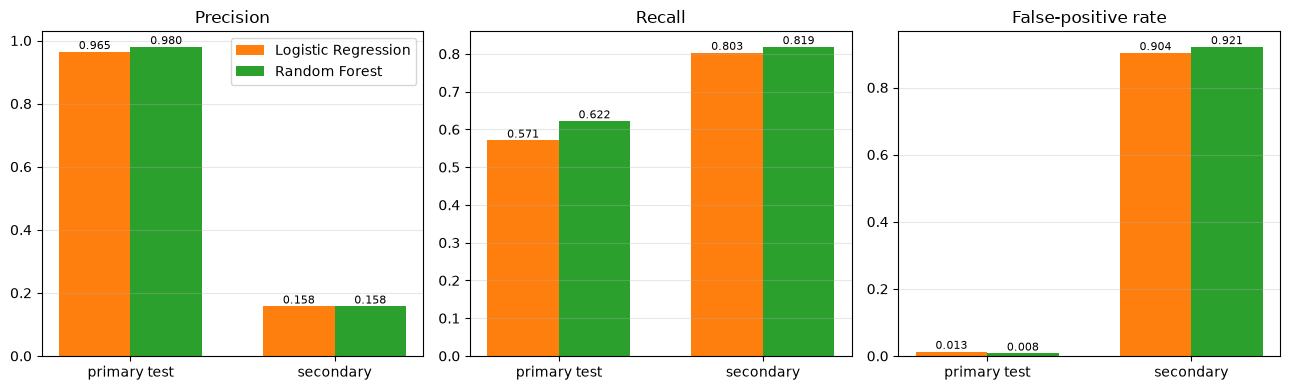

In [21]:
tuned_rows = results[results["threshold_type"] == "tuned"]
metrics_to_plot = ["precision", "recall", "fpr"]
titles = {"precision": "Precision", "recall": "Recall", "fpr": "False-positive rate"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
width = 0.35
x = np.arange(2)
for ax, metric in zip(axes, metrics_to_plot):
    for i, name in enumerate(best_models):
        vals = [tuned_rows[(tuned_rows["dataset"] == ds) & (tuned_rows["model"] == name)][metric].iloc[0] for ds in eval_sets]
        bars = ax.bar(x + i * width - width / 2, vals, width, label=name, color=colors[name])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(["primary test", "secondary"])
    ax.set_title(titles[metric])
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "model_comparison.png", dpi=150)
plt.show()

### Confusion Matrices

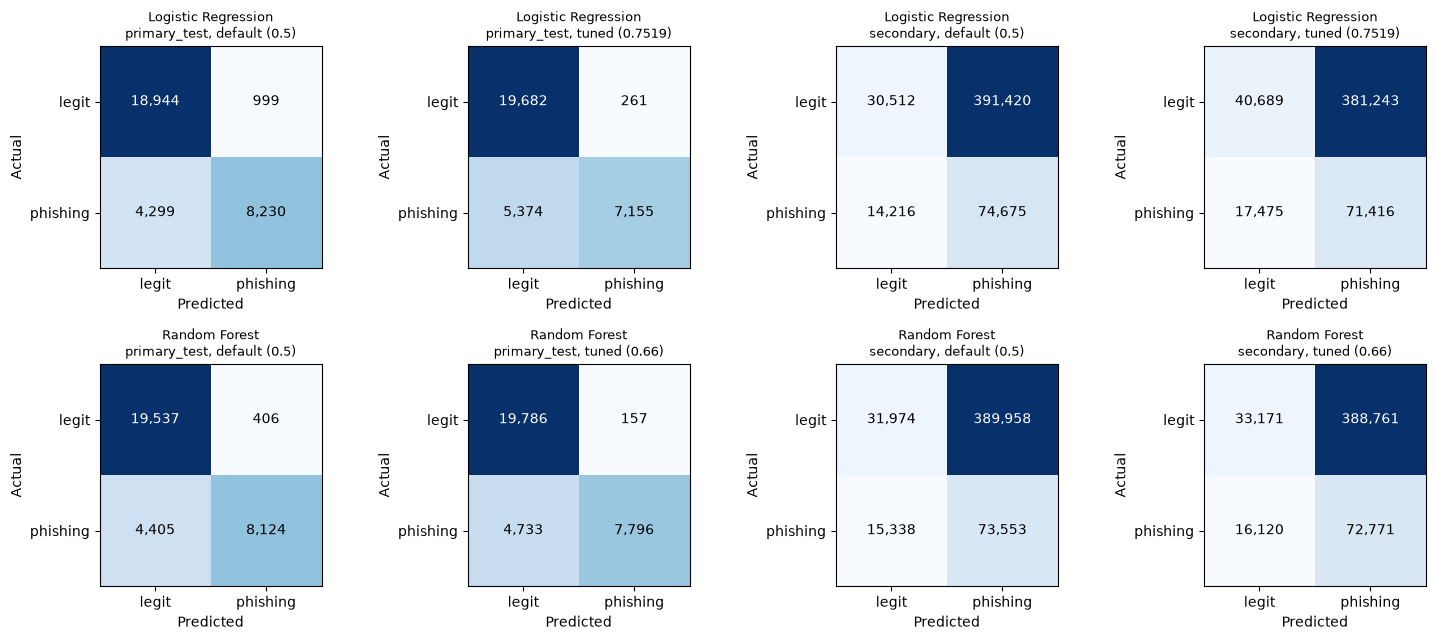

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for r, name in enumerate(best_models):
    c = 0
    for ds in eval_sets:
        for kind in ("default", "tuned"):
            row = results[(results["dataset"] == ds) & (results["model"] == name) & (results["threshold_type"] == kind)].iloc[0]
            cm = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
            ax = axes[r, c]
            ax.imshow(cm, cmap="Blues")
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                            color="white" if cm[i, j] > cm.max() / 2 else "black")
            ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
            ax.set_xticklabels(["legit", "phishing"]); ax.set_yticklabels(["legit", "phishing"])
            ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
            ax.set_title(f"{name}\n{ds}, {kind} ({row['threshold']})", fontsize=9)
            c += 1
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

### What the Models Learned (feature importance)
Logistic Regression coefficients show direction (positive = pushes toward phishing). Random Forest importances show how much a feature is used. These are indicators only, not proof of malicious intent.

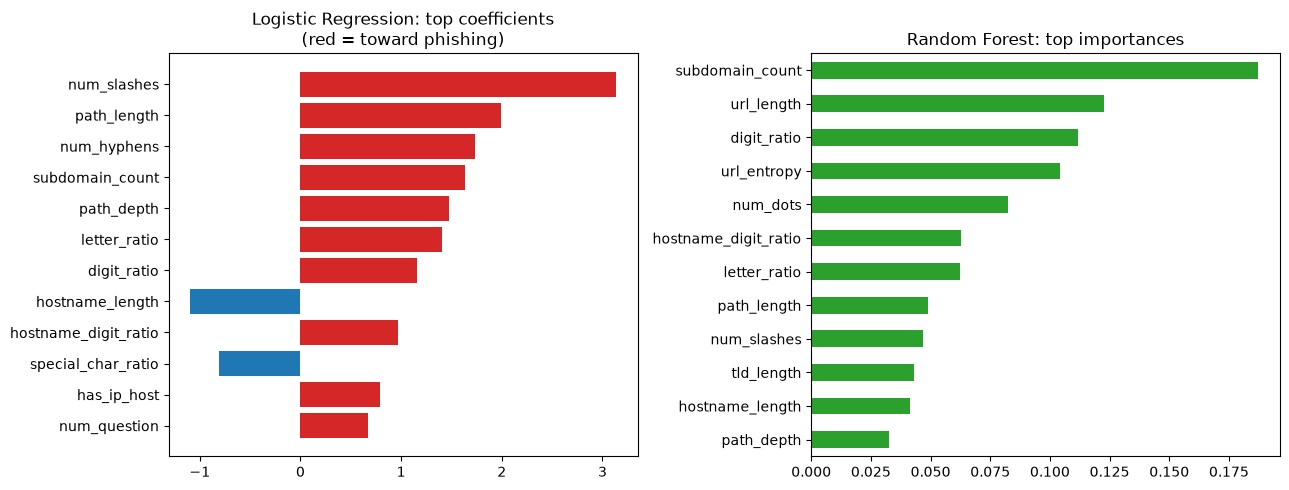

In [23]:
lr_coef = pd.Series(best_models["Logistic Regression"].named_steps["model"].coef_[0], index=FEATURES)
rf_imp = pd.Series(best_models["Random Forest"].feature_importances_, index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_lr = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index[:12])[::-1]
axes[0].barh(top_lr.index, top_lr.values, color=["tab:red" if v > 0 else "tab:blue" for v in top_lr.values])
axes[0].set_title("Logistic Regression: top coefficients\n(red = toward phishing)")
rf_imp.sort_values().tail(12).plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title("Random Forest: top importances")
plt.tight_layout()
plt.savefig(OUT_DIR / "feature_importance.png", dpi=150)
plt.show()

### Error Analysis (secondary dataset, Random Forest, tuned threshold)
Looking at the mistakes shows what URL text alone cannot reveal. Expect missed phishing links that look like ordinary short URLs, and legitimate links with long, parameter-heavy paths.

In [24]:
t = frozen["thresholds"]["Random Forest"]["tuned"]
err = secondary_t[["url", "phish"]].copy()
err["score"] = test_scores[("secondary", "Random Forest")]
err["flagged"] = (err["score"] >= t).astype(int)

missed = err[(err["phish"] == 1) & (err["flagged"] == 0)].sort_values("score").head(10)
false_alarms = err[(err["phish"] == 0) & (err["flagged"] == 1)].sort_values("score", ascending=False).head(10)

print("Phishing URLs the model missed (lowest scores):")
for u, s in zip(missed["url"], missed["score"]):
    print(f"  {s:.3f}  {u[:100]}")
print("\nLegitimate URLs wrongly flagged (highest scores):")
for u, s in zip(false_alarms["url"], false_alarms["score"]):
    print(f"  {s:.3f}  {u[:100]}")

Phishing URLs the model missed (lowest scores):
  0.069  csc.com.np
  0.070  vkvk.pe.hu
  0.070  aads.co.id
  0.070  cpi.com.my
  0.070  isb.ens.tn
  0.070  http://p.wpage.cc/
  0.072  lle.com.pk
  0.072  wfc.com.pk
  0.072  http://f.qtrip.cc/
  0.072  mite.ac.in

Legitimate URLs wrongly flagged (highest scores):
  1.000  allmusic.com/album/crazy-from-the-heat-r16990
  1.000  paypal-confirmation.it.kizitowangalwa.co.ke/confirmation/6a9562a8bb2ec772cf2db78aea520ab1/Processing
  1.000  myspace.com/video/vid/30602581
  1.000  www.citizdrav.ru/templates/rhuk_milkyway/sincronizador30horas/
  1.000  192.com/atoz/people/oakley/patrick/
  1.000  linkedin.com/pub/eric-lecompte/2a/4a5/a15
  1.000  https://500px.com/photo/17379505/escalera-al-mar-by-dragox-photo-?from=set&set_id=253106
  1.000  http://pornsharing.com/blonde-layla-price-loves-glass-dildo-in-her-pink-asshole_v78459
  1.000  therpf.com/f24/ny-comiccon-roll-call-129014/
  1.000  rapradar.com/2011/09/13/game-reveals-title-of-next-albu

**About label quality.** Some URLs labeled legitimate in the secondary dataset and flagged by the model look like phishing (for example a `paypal-confirmation...` hostname), which suggests some benign labels may be wrong. Appearance alone does not prove that, because the URLs were not verified here. Likewise, a bare domain labeled phishing is not evidence of a wrong label: it may be a compromised legitimate site that simply has a plain-looking URL. Treat the secondary scores as a stress test on imperfect labels, not as an exact accuracy.

### Diagnosis: Why Does Performance Change So Much on the Secondary Data?

The feature importance chart shows the models lean heavily on `num_slashes` and `path_length`, and the discrepancy table shows PhiUSIIL's legitimate URLs are very short. The hypothesis: **in PhiUSIIL almost every legitimate URL is a bare homepage and phishing URLs tend to have paths, so the models learned "has a path = phishing".** The secondary dataset's legitimate URLs often have paths, and many of its phishing URLs are bare domains.

This cell tests that by splitting each dataset into **bare-domain URLs** (no path, no query) and **URLs with a path or query**, then measuring how often each group is flagged (tuned threshold). Nothing here changes the frozen models.

In [25]:
def has_path(df):
    return ((df["path_length"] > 1) | (df["query_length"] > 0)).astype(int)

diag_rows = []
for ds, df in (("primary_test", test_primary), ("secondary", secondary_t)):
    path_flag = has_path(df).values
    for name in best_models:
        flagged = test_scores[(ds, name)] >= frozen["thresholds"][name]["tuned"]
        for cls_name, cls_val in (("legitimate", 0), ("phishing", 1)):
            in_class = df["phish"].values == cls_val
            for group, g in (("bare domain", 0), ("has path/query", 1)):
                mask = in_class & (path_flag == g)
                diag_rows.append({
                    "dataset": ds, "model": name, "class": cls_name, "group": group,
                    "n": int(mask.sum()),
                    "share_of_class": mask.sum() / in_class.sum(),
                    "flag_rate": flagged[mask].mean() if mask.sum() else np.nan,
                })

diagnosis = pd.DataFrame(diag_rows)
diagnosis.to_csv(OUT_DIR / "diagnosis_path_shortcut.csv", index=False)
diagnosis[diagnosis["model"] == "Random Forest"].drop(columns="model").round(3)

,dataset,class,group,n,share_of_class,flag_rate
4,primary_test,legitimate,bare domain,19943,1.000,0.008
5,primary_test,legitimate,has path/query,0,0.000,NaN
6,primary_test,phishing,bare domain,7114,0.568,0.335
7,primary_test,phishing,has path/query,5415,0.432,1.000
12,secondary,legitimate,bare domain,46168,0.109,0.282
13,secondary,legitimate,has path/query,375764,0.891,1.000
14,secondary,phishing,bare domain,22991,0.259,0.299
15,secondary,phishing,has path/query,65900,0.741,1.000


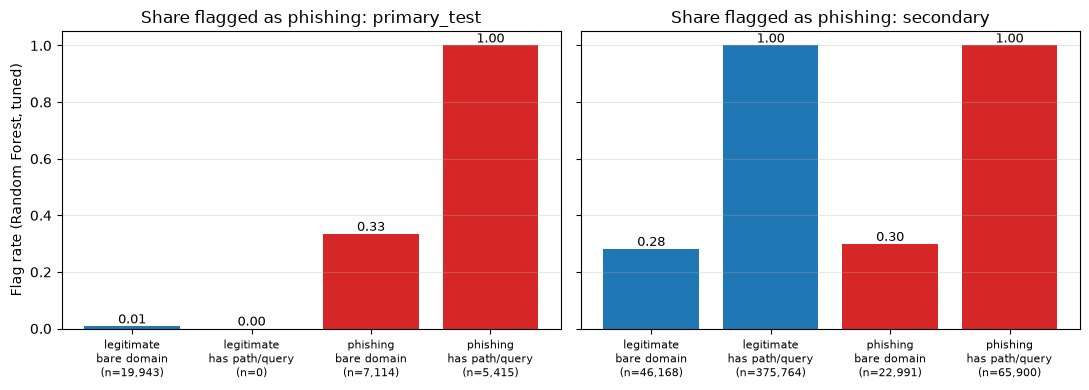

In [26]:
rf_diag = diagnosis[diagnosis["model"] == "Random Forest"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, ["primary_test", "secondary"]):
    sub = rf_diag[rf_diag["dataset"] == ds]
    labels, vals, cols = [], [], []
    for cls_name, color in (("legitimate", "tab:blue"), ("phishing", "tab:red")):
        for group in ("bare domain", "has path/query"):
            row = sub[(sub["class"] == cls_name) & (sub["group"] == group)].iloc[0]
            labels.append(f"{cls_name}\n{group}\n(n={row['n']:,})")
            vals.append(0 if np.isnan(row["flag_rate"]) else row["flag_rate"])
            cols.append(color)
    bars = ax.bar(range(4), vals, color=cols)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(4))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(f"Share flagged as phishing: {ds}")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Flag rate (Random Forest, tuned)")
plt.tight_layout()
plt.savefig(OUT_DIR / "diagnosis_path_shortcut.png", dpi=150)
plt.show()

**How to read this:** if legitimate URLs *with a path* are flagged far more than legitimate *bare domains*, and phishing bare domains are rarely flagged, the models are keying on URL shape instead of phishing behavior. The `share_of_class` column shows how few primary-set legitimate URLs have a path at all, which is why the models never learned what a normal legitimate path looks like.

**How to read the table and chart above:** look at `share_of_class` for legitimate URLs in the primary test set. If it shows (almost) no legitimate URLs with a path, the models never saw what a normal legitimate path looks like and are partly keying on "has a path". Then check whether legitimate **bare-domain** URLs are flagged differently in the two datasets. If they are, something other than the path differs between the sources. The next cell checks the most likely candidates, including a trailing `/`, which changes `num_slashes` (a top feature) for the same homepage. In v1 of this project this check found a trailing-slash difference that led to the v2 preprocessing fix (see the change log).

### Diagnosis, Part 2: What Differs Between the Two Datasets' Bare-Domain Legitimate URLs?
Compares primary legitimate URLs against secondary legitimate bare-domain URLs on the main features, and checks how often a trailing slash explains the flagging. Nothing here changes the frozen models.

In [27]:
prim_legit = test_primary[test_primary["phish"] == 0]
sec_legit_bare = secondary_t[(secondary_t["phish"] == 0) & (has_path(secondary_t) == 0)]

compare_cols = ["url_length", "num_slashes", "hostname_length", "subdomain_count",
                "num_dots", "num_hyphens", "digit_ratio", "url_entropy"]
compare = pd.DataFrame({
    "primary legit (all bare)": prim_legit[compare_cols].median(),
    "secondary legit, bare": sec_legit_bare[compare_cols].median(),
}).T
compare["share_ending_in_slash"] = [
    prim_legit["key"].str.endswith("/").mean(),
    sec_legit_bare["key"].str.endswith("/").mean(),
]
display(compare.round(3))

# Flag rate of secondary bare-domain legitimate URLs, split by trailing slash (Random Forest, tuned threshold)
thr = frozen["thresholds"]["Random Forest"]["tuned"]
flag = test_scores[("secondary", "Random Forest")] >= thr
bare_legit_mask = ((secondary_t["phish"] == 0) & (has_path(secondary_t) == 0)).values
slash_mask = secondary_t["key"].str.endswith("/").values

slash_rows = []
for label, m in (("ends with '/'", bare_legit_mask & slash_mask), ("no trailing '/'", bare_legit_mask & ~slash_mask)):
    slash_rows.append({"secondary legit bare-domain group": label, "n": int(m.sum()),
                       "flag_rate": flag[m].mean() if m.sum() else np.nan})
slash_table = pd.DataFrame(slash_rows)
slash_table.to_csv(OUT_DIR / "diagnosis_trailing_slash.csv", index=False)
slash_table.round(3)

,url_length,num_slashes,hostname_length,subdomain_count,num_dots,num_hyphens,digit_ratio,url_entropy,share_ending_in_slash
primary legit (all bare),15.0,0.0,15.0,0.0,1.0,0.0,0.0,3.346,0.0
"secondary legit, bare",19.0,0.0,19.0,0.0,1.0,0.0,0.0,3.550,0.0


,secondary legit bare-domain group,n,flag_rate
0,ends with '/',0,NaN
1,no trailing '/',46168,0.282


### Post-hoc Experiment: Hostname-Only Features (NOT used for model selection)

If the path shortcut is the problem, removing the path and query features should reduce it. This trains the same two models, with the **same already-selected settings**, on only 7 hostname-level features:
`hostname_length`, `subdomain_count`, `tld_length`, `hostname_digit_ratio`, `has_ip_host`, `has_port`, `is_shortener`.

Important caveats:
- This experiment was designed **after** seeing the secondary results, so it is **post-hoc**. It does not replace the frozen models, is not deployed, and must not be presented as a tuned result.
- Its threshold is still picked on validation data only (1% false-positive budget). The secondary set is not used to choose anything.
- Fewer features will probably lower primary performance. The question is whether the secondary result stops collapsing.

In [28]:
HOST_FEATURES = ["hostname_length", "subdomain_count", "tld_length", "hostname_digit_ratio",
                 "has_ip_host", "has_port", "is_shortener"]

posthoc_rows = []
for name, (builder, _) in GRIDS.items():
    model = builder(**best_params[name])
    model.fit(train[HOST_FEATURES], y_train)
    t = pick_threshold(y_val, model.predict_proba(val[HOST_FEATURES])[:, 1])
    for ds, df in (("primary_test", test_primary), ("secondary", secondary_t)):
        scores = model.predict_proba(df[HOST_FEATURES])[:, 1]
        posthoc_rows.append({"feature_set": "hostname-only (post-hoc)", "dataset": ds, "model": name,
                             "threshold": round(t, 4), **evaluate(df["phish"], scores, t)})

full_tuned = results[results["threshold_type"] == "tuned"].copy()
full_tuned.insert(0, "feature_set", "all 24 (frozen, deployed)")
posthoc = pd.concat([full_tuned.drop(columns="threshold_type"), pd.DataFrame(posthoc_rows)], ignore_index=True)
posthoc = posthoc[["feature_set", "dataset", "model", "threshold", "precision", "recall", "f1", "fpr", "ap"]]
posthoc = posthoc.sort_values(["dataset", "model", "feature_set"]).reset_index(drop=True)
posthoc.to_csv(OUT_DIR / "posthoc_hostname_only.csv", index=False)
posthoc.round(3)

,feature_set,dataset,model,threshold,precision,recall,f1,fpr,ap
0,"all 24 (frozen, deployed)",primary_test,Logistic Regression,0.752,0.965,0.571,0.717,0.013,0.849
1,hostname-only (post-hoc),primary_test,Logistic Regression,0.845,0.918,0.228,0.365,0.013,0.683
2,"all 24 (frozen, deployed)",primary_test,Random Forest,0.660,0.980,0.622,0.761,0.008,0.873
3,hostname-only (post-hoc),primary_test,Random Forest,0.798,0.968,0.353,0.517,0.007,0.762
4,"all 24 (frozen, deployed)",secondary,Logistic Regression,0.752,0.158,0.803,0.264,0.904,0.129
5,hostname-only (post-hoc),secondary,Logistic Regression,0.845,0.312,0.129,0.183,0.060,0.211
6,"all 24 (frozen, deployed)",secondary,Random Forest,0.660,0.158,0.819,0.264,0.921,0.122
7,hostname-only (post-hoc),secondary,Random Forest,0.798,0.203,0.189,0.196,0.156,0.206


### 9. Generalizability & Business Interpretation

The secondary dataset (Kaggle Malicious URLs) comes from different sources and collection methods than PhiUSIIL, so this tests **generalization across data sources**, not future phishing attacks. A performance drop is a finding to explain, not something to hide.

The false-positive rate is translated into analyst workload. Precision on a test set depends on how much phishing it contains, and real inboxes contain far less phishing than these datasets, so the last two columns use an assumed **1% phishing prevalence** (`PREVALENCE` in the settings cell). That number is an illustration and not a measured value.

In [29]:
business = results.copy()
business["phish_caught_per_1000_phish"] = (business["recall"] * 1000).round(0)
business["phish_missed_per_1000_phish"] = ((1 - business["recall"]) * 1000).round(0)
business["unnecessary_reviews_per_1000_legit"] = (business["fpr"] * 1000).round(1)

flagged_per_1000 = 1000 * (PREVALENCE * business["recall"] + (1 - PREVALENCE) * business["fpr"])
true_flags_per_1000 = 1000 * PREVALENCE * business["recall"]
business["assumed_alerts_per_1000_urls"] = flagged_per_1000.round(1)
business["assumed_alert_precision"] = (true_flags_per_1000 / flagged_per_1000).round(3)

business = business[["dataset", "model", "threshold_type", "recall", "fpr",
                    "phish_caught_per_1000_phish", "phish_missed_per_1000_phish",
                    "unnecessary_reviews_per_1000_legit",
                    "assumed_alerts_per_1000_urls", "assumed_alert_precision"]]
business.to_csv(OUT_DIR / "business_view.csv", index=False)
business.round(3)

,dataset,model,threshold_type,recall,fpr,phish_caught_per_1000_phish,phish_missed_per_1000_phish,unnecessary_reviews_per_1000_legit,assumed_alerts_per_1000_urls,assumed_alert_precision
0,primary_test,Logistic Regression,default,0.657,0.050,657.0,343.0,50.1,56.2,0.117
1,primary_test,Logistic Regression,tuned,0.571,0.013,571.0,429.0,13.1,18.7,0.306
2,primary_test,Random Forest,default,0.648,0.020,648.0,352.0,20.4,26.6,0.243
3,primary_test,Random Forest,tuned,0.622,0.008,622.0,378.0,7.9,14.0,0.444
4,secondary,Logistic Regression,default,0.840,0.928,840.0,160.0,927.7,926.8,0.009
5,secondary,Logistic Regression,tuned,0.803,0.904,803.0,197.0,903.6,902.6,0.009
6,secondary,Random Forest,default,0.827,0.924,827.0,173.0,924.2,923.3,0.009
7,secondary,Random Forest,tuned,0.819,0.921,819.0,181.0,921.4,920.4,0.009


**Reading the business table:** on the primary test set, the tuned Random Forest keeps unnecessary reviews low. On the secondary set, the false-positive rate is close to 100% for both models, meaning almost every legitimate URL would be flagged. In practice this tool would be **unusable on data that does not look like its training data**, and an analyst queue full of false alarms is worse than no tool. The honest business message is that a strong score on one dataset does not guarantee value in a new environment, and that models like this need training data that matches the traffic they will see.

### Inference Latency
Measured the way the app works: one URL at a time, including feature extraction, with the Random Forest running single-threaded as it does in the app (`n_jobs=1`; spreading 200 trees across worker threads costs more than it saves for a single URL). Latency depends on the machine and the run, so quote the numbers from this table and not from memory.

In [30]:
sample_urls = secondary_t["url"].sample(min(200, len(secondary_t)), random_state=SEED).tolist()
latency_rows = []
for name, model in best_models.items():
    served = deepcopy(model)                                 # time the model as the app serves it
    if name == "Random Forest":
        served.set_params(n_jobs=1)
    phish_score(served, sample_urls[:1])                     # warm-up
    times = []
    for u in sample_urls:
        start = time.perf_counter()
        phish_score(served, [u])
        times.append((time.perf_counter() - start) * 1000)
    latency_rows.append({"model": name, "median_ms": np.median(times), "p95_ms": np.percentile(times, 95)})

latency = pd.DataFrame(latency_rows)
latency.to_csv(OUT_DIR / "latency.csv", index=False)
latency.round(2)

,model,median_ms,p95_ms
0,Logistic Regression,7.70,10.99
1,Random Forest,48.82,83.80


### Save Model Artifacts for the App

In [31]:
for name, model in best_models.items():
    file_name = "logistic_regression.joblib" if name == "Logistic Regression" else "random_forest.joblib"
    joblib.dump(model, MODEL_DIR / file_name)

# make sure the saved models give identical scores after reloading
check_urls = val["url"].head(50).tolist()
for name, file_name in (("Logistic Regression", "logistic_regression.joblib"), ("Random Forest", "random_forest.joblib")):
    reloaded = joblib.load(MODEL_DIR / file_name)
    assert np.allclose(phish_score(reloaded, check_urls), phish_score(best_models[name], check_urls))

print("Saved to", MODEL_DIR)
print(sorted(p.name for p in MODEL_DIR.iterdir()))

# Align the deployment environment with the training environment recorded in config.json
if MOCK:
    print("Mock mode: requirements.txt and Dockerfile left untouched.")
else:
    versions = config["versions"]
    python_minor = ".".join(versions["python"].split(".")[:2])

    req_path = DEPLOY_DIR / "requirements.txt"
    kept = [line for line in req_path.read_text().splitlines() if line.startswith("gradio")]
    pinned = [f"scikit-learn=={versions['scikit-learn']}", f"pandas=={versions['pandas']}",
              f"numpy=={versions['numpy']}", f"joblib=={versions['joblib']}"]
    req_path.write_text("\n".join(kept + pinned) + "\n")

    docker_path = DEPLOY_DIR / "Dockerfile"
    docker_path.write_text(re.sub(r"^FROM python:\S+", f"FROM python:{python_minor}-slim", docker_path.read_text(), flags=re.M))

    print(f"requirements.txt pinned to the training environment: {pinned}")
    print(f"Dockerfile base image set to python:{python_minor}-slim")

Saved to deploy\models
['config.json', 'logistic_regression.joblib', 'random_forest.joblib']
requirements.txt pinned to the training environment: ['scikit-learn==1.9.0', 'pandas==3.0.3', 'numpy==2.4.6', 'joblib==1.5.3']
Dockerfile base image set to python:3.14-slim


### 10. Production Deployment

The deployed app lives in `deploy/` and is a Gradio interface packaged with Docker for Hugging Face Spaces.

| File | Purpose |
|---|---|
| `app.py` | Gradio app: URL input, model selector, threshold choice, phishing score, flagged / not flagged result, observable URL characteristics, inference time, example URLs |
| `features.py` | Shared URL-only feature code (identical to what training used) |
| `models/` | Saved models + `config.json` (frozen settings and thresholds). Created by this notebook. |
| `requirements.txt` | Dependencies. The scikit-learn, pandas, numpy and joblib pins are written by this notebook from the training environment. |
| `Dockerfile` | Container definition (port 7860). Its Python version is set from the training environment, and the build runs the tests below. |
| `test_features.py` | Tests for URL normalization, input validation and feature extraction |
| `smoke_test.py` | End-to-end check of the package: versions match training, both models load and score, bad input is rejected cleanly |
| `README.md` | Hugging Face Space config + deployment steps |

**Training and deployment must match.** A saved scikit-learn model is only guaranteed to work with the version that saved it, and loading without an error does not prove compatibility. The app therefore compares the installed Python, scikit-learn, numpy, pandas and joblib versions with `config.json` and refuses to start if they differ. The Docker build runs `smoke_test.py`, so a mismatched package fails the build instead of failing in production.

See `deploy/README.md` for the step-by-step deployment instructions. The app only analyzes the text of the URL, never visits it, and is an advisory triage aid.

### Key Findings
1. **Primary test set:** URL-only features separate phishing from legitimate URLs reasonably well. The tuned Random Forest meets the ~1% false-positive budget with high precision but only moderate recall (see the results table).
2. **Random Forest beat Logistic Regression** on validation and primary test Average Precision (AP). Latency depends on the machine, so use the latency table.
3. **Generalization failed.** On the secondary dataset both models flag most legitimate URLs, and AP falls below the secondary phishing base rate.
4. **Main cause: the path shortcut.** The primary test set contains no legitimate URLs with a path or query, so the models learned that a path means phishing (see the diagnosis sections and the change log).
5. **Hostname-only experiment (post-hoc):** removing path and query features changes the false-positive rate but at a large cost in recall (see the table). It is exploratory and not part of the frozen evaluation.
6. **Possible label noise in the secondary dataset** (see the error analysis). The labels were not verified.
7. **Deployment implication:** as trained, the model is **unsuitable for operational triage**. It over-flags ordinary URLs with paths, and it should not be used without retraining on data whose legitimate URLs look like real traffic. Discovering and explaining this is itself a valid result of the evaluation.

### Limitations
- Both datasets are historical and collected with different methods, so scores on them do not predict performance on today's phishing.
- Labels are imperfect and were not verified. Some "legitimate" URLs may be malicious and vice versa, and some suspicious-looking benign examples in the secondary dataset suggest possible mislabeling. A bare domain labeled phishing is not by itself evidence of a wrong label.
- PhiUSIIL's legitimate URLs are bare homepages (100% `https` and `www`, median length 15, none with a path in the test set), so the models can learn URL shape instead of phishing behavior. This is the main reason generalization failed.
- The two datasets have very different phishing rates (about 41% vs 17%), so precision is not directly comparable between them.
- **Secondary-test independence:** the secondary dataset was excluded from model fitting and from hyperparameter and threshold selection. However, its initial results informed the v2 normalization change and the post-hoc diagnostics, so the v2 and v3 evaluations are exploratory external evaluations rather than fully untouched tests. A newly reserved external dataset would be needed for a fresh blind assessment.
- The hostname-only experiment was designed after seeing the secondary results, so it is exploratory.
- Removing the scheme, `www.` and a root trailing slash are modeling decisions to unify two datasets, not claims that those URLs are always equivalent.
- Phishing hosted on legitimate domains, or hidden behind shorteners, cannot be recognized from URL text alone.
- Feature-based models can be probed by an attacker who knows the features. Adversarial robustness was not tested here (an optional extension).
- Results show a reproducible component and a working triage prototype, not a full enterprise security product. Specific accuracy or breach-reduction claims are out of scope.

### Future Work: A Better Training Dataset Before Any Added Model Complexity
The main problem is the data, not the model. For a future version:
1. Train on legitimate URLs that look like real browsing traffic, including paths and query strings, alongside phishing URLs of every shape (bare domains and long paths).
2. Reserve a separate, newly collected evaluation set that is never used to make design choices, so a blind assessment is possible.
3. Verify a sample of labels by hand, especially suspicious-looking "legitimate" URLs and plain-looking "phishing" domains.
4. Only then consider richer models or features (page content, sender and domain reputation), and test robustness against shortened, mutated and look-alike URLs.

### References
- PhiUSIIL Phishing URL Dataset: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset
- ISCX-URL2016 (Canadian Institute for Cybersecurity, UNB), evaluated but not used: https://www.unb.ca/cic/datasets/url-2016.html
- Malicious URLs dataset (Kaggle, `malicious_phish.csv`): https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset
- Hugging Face Docker Spaces: https://huggingface.co/docs/hub/en/spaces-sdks-docker
- Gradio + Hugging Face: https://gradio.app/guides/using-hugging-face-integrations

### Generative AI Disclosure
Generative AI was used in a few ways:
1. There were a few instances where through my own research I could not find bugs in my code. Copilot was used to assist me in fixing my code in those cases.
2. I used AI to help fix grammar and spelling.
3. After writing out the contents of tables in a google doc, I asked AI to take the information and format it into a table. 
4. I used AI to check if I satisfied requriments for the assignment, and took it's suggestions for where I fell short.
5. While still keeping most of my original code, I had AI make it more readable for human interpretation (for ease of grading).